# Rerankers

**Summary** (dev, 241 queries, off-the-shelf rerankers on the first stage's top 100)
- **15 rerankers of six types**, 0.15B–8B, each re-sorting the top 100 from BM25 + inf-1.5B + arctic-m (nDCG@10 **0.780**).
- **Reranking the top 100 makes the top 10 significantly worse for 12 of 15 models**; none is significantly better.
- **The deeper they rerank, the worse it gets.** At depth 10 most are level with the first stage; only **zerank-2 is significantly better (+0.9, p=0.008)**.
- **zerank-2 is too slow to keep**: about 470 ms at depth 10 (estimated), almost the whole 500 ms budget, for +0.9 points. Rerankers are revisited after LLM query and product expansion.

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd

from product_search.data.splits import load_split
from product_search.data.wands import label_grades, load_wands
from product_search.eval.metrics import per_query_metrics, rank
from product_search.eval.stats import bootstrap_ci, paired_permutation_test
from product_search.retrieval.fusion import rrf
from product_search.runs import RUNS_DIR, load_results, read_json

RULE_P = 0.05
BUDGET_MS = 500
FIRST_STAGE_MS = 37.4
FIRST_STAGE = ("bm25_default", "dense_inf_15b", "dense_arctic_m")
DEPTHS = (10, 20, 50, 100)
# run: (label, type, total parameters, active parameters, precision, chosen from)
MODELS = {
    "rerank_modern_colbert": (
        "GTE-ModernColBERT",
        "late interaction",
        0.149,
        None,
        "fp32",
        "added: method coverage",
    ),
    "rerank_gte_modernbert": (
        "gte-reranker-modernbert",
        "cross-encoder, BERT",
        0.150,
        None,
        "bf16",
        "added: modern BERT-type",
    ),
    "rerank_bge_v2_m3": (
        "bge-reranker-v2-m3",
        "cross-encoder, BERT",
        0.568,
        None,
        "bf16",
        "AIR-Bench",
    ),
    "rerank_mxbai_base": (
        "mxbai-rerank-base-v2",
        "cross-encoder, LLM",
        0.494,
        None,
        "bf16",
        "KaLM paper",
    ),
    "rerank_qwen3_06b": (
        "Qwen3-Reranker-0.6B",
        "cross-encoder, LLM",
        0.596,
        None,
        "bf16",
        "Qwen3 card, KaLM paper",
    ),
    "rerank_mxbai_large": (
        "mxbai-rerank-large-v2",
        "cross-encoder, LLM",
        1.54,
        None,
        "bf16",
        "KaLM paper",
    ),
    "rerank_zerank2": (
        "zerank-2",
        "cross-encoder, LLM",
        4.02,
        None,
        "bf16",
        "Agentset leaderboard",
    ),
    "rerank_qwen3_4b": (
        "Qwen3-Reranker-4B",
        "cross-encoder, LLM",
        4.02,
        None,
        "bf16",
        "Qwen3 card, KaLM paper",
    ),
    "rerank_qwen3_8b": (
        "Qwen3-Reranker-8B",
        "cross-encoder, LLM",
        8.19,
        None,
        "8-bit",
        "Qwen3 card, KaLM paper",
    ),
    "rerank_lychee_n": ("Lychee-N", "partly cross", 0.786, 0.27, "bf16", "KaLM paper"),
    "rerank_lychee_s": ("Lychee-S", "partly cross", 2.12, 1.0, "bf16", "KaLM paper"),
    "rerank_lychee_l": ("Lychee-L", "partly cross", 7.51, 4.0, "8-bit", "KaLM paper"),
    "rerank_jina_v3": (
        "jina-reranker-v3",
        "listwise",
        0.597,
        None,
        "bf16",
        "added: method coverage",
    ),
    "rerank_inf_7b": (
        "inf-retriever-v1 (7B)",
        "bi-encoder",
        7.1,
        None,
        "8-bit",
        "notebook 04: best dense",
    ),
    "rerank_qwen3_emb_4b": (
        "Qwen3-Embedding-4B",
        "bi-encoder",
        4.02,
        None,
        "bf16",
        "control for Qwen3-Reranker-4B",
    ),
}
LISTWISE = {"rerank_jina_v3"}
COLOURS = {
    "cross-encoder, BERT": "#2a78d6",
    "cross-encoder, LLM": "#eb6834",
    "partly cross": "#1baf7a",
    "listwise": "#6250d6",
    "late interaction": "#eda100",
    "bi-encoder": "#888780",
}
MARKERS = {
    "cross-encoder, BERT": "s",
    "cross-encoder, LLM": "o",
    "partly cross": "^",
    "listwise": "P",
    "late interaction": "D",
    "bi-encoder": "v",
}
GREEN, RED = "#d6f0d6", "#f7d4d4"
LABEL = {run: m[0] for run, m in MODELS.items()}
TYPE = {run: m[1] for run, m in MODELS.items()}

dev = load_split().dev
labels = label_grades(load_wands().labels)
fused = rrf([load_results(RUNS_DIR / run / "results.parquet") for run in FIRST_STAGE])
first = {q: fused[q] for q in dev}
first_order = rank(first)
reranked = {run: load_results(RUNS_DIR / run / "results.parquet") for run in MODELS}
p99 = {
    run: read_json(RUNS_DIR / run / "meta.json")["cost"]["rerank_latency"]["p99_ms"]
    for run in MODELS
}


def ndcg(results: dict) -> pd.Series:
    """Per-query nDCG@10 on dev."""
    return per_query_metrics(results, labels, dev)["nDCG@10"]


def at_depth(run: str, depth: int) -> dict:
    """Rerank only the top depth with the saved scores; the rest keeps first-stage order.

    Valid for pointwise rerankers, whose score for a product does not depend on
    the other candidates.
    """
    scores = reranked[run]
    out = {}
    for q in dev:
        head = sorted(first_order[q][:depth], key=lambda p: -scores[q][p])
        out[q] = {p: -i for i, p in enumerate(head + first_order[q][depth:])}
    return out


def final(run: str) -> dict:
    """The run's reranked top 100, ties in the reranker's score kept in first-stage order.

    bf16 scores from the LLM rerankers often tie; breaking ties by first-stage
    rank is fairer than by product id. Listwise scores depend on the whole
    list, so jina-reranker-v3 is used as saved.
    """
    return reranked[run] if run in LISTWISE else at_depth(run, 100)


base = ndcg(first)


def against_first(scores: pd.Series) -> tuple[float, float]:
    """Difference to the first stage in points and permutation-test p-value."""
    diff, p = paired_permutation_test(base, scores)
    return round(diff * 100, 1), round(p, 3)


def p_text(p: float) -> str:
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"


def type_style(kind: str) -> str:
    return f"color: {COLOURS[kind]}; font-weight: bold"


def size_style(billions: float) -> str:
    """Purple shade by parameter count on a log scale, 0.15B light to 8B dark."""
    share = (math.log10(billions) - math.log10(0.1)) / (math.log10(10) - math.log10(0.1))
    r, g, b, _ = plt.cm.Purples(0.1 + 0.55 * share)
    return f"background-color: rgb({r * 255:.0f}, {g * 255:.0f}, {b * 255:.0f})"


def significance_colours(row: pd.Series) -> list[str]:
    """Green on a Δ/p pair when significantly better, red when significantly worse."""
    styles = pd.Series("", index=row.index)
    for column in row.index:
        if column.startswith("p ") and pd.notna(row[column]) and row[column] < RULE_P:
            delta = "Δ " + column[2:]
            styles[[delta, column]] = f"background-color: {GREEN if row[delta] > 0 else RED}"
    return styles.tolist()


def budget_style(ms: float) -> str:
    return f"background-color: {GREEN if ms <= BUDGET_MS else RED}"

## 1. Setup

**Two steps.** The first stage (notebook 05) searches all 43k products and returns a ranked list in 37 ms. A **reranker** takes that list's **top 100** and sorts it again with a slower, stronger model; the first-stage order is replaced. Products below 100 keep their first-stage order.

**Metric: nDCG@10**, the quality of the final top 10. Products with the same reranker score keep their first-stage order. Rcap@100 cannot change: reranking only re-sorts the same 100 products (it stays 0.775 for every model).

**Budget:** p99 ≤ 500 ms per query for the whole system, first stage included. Queries are reranked one at a time, as in serving, on the tower with background apps closed. All models are used off the shelf: no training on WANDS, no changes to queries or product texts.

## 2. How the models were chosen

**Sources:** the [AIR-Bench leaderboard](https://huggingface.co/spaces/AIR-Bench/leaderboard) (Hugging Face), the [Agentset reranker leaderboard](https://benchmarklist.com/benchmarks/agentset_reranker_leaderboard/) (via benchmarklist), the [Qwen3-Reranker model cards](https://huggingface.co/Qwen/Qwen3-Reranker-4B) and the [KaLM / Lychee reranker paper](https://arxiv.org/abs/2606.22807), which compares 13 open rerankers on BEIR. Three models were **added to cover methods** none of the sources had: a late-interaction model, a listwise model and a current BERT-type cross-encoder. Two bi-encoders come from notebook 04.

**Six ways to score a product:**
- **Cross-encoder, BERT-type**: a small encoder reads query and product together; a head turns that into a score.
- **Cross-encoder, LLM**: a language model reads query and product together and is asked "relevant? yes or no"; the score is how strongly it says yes.
- **Partly cross** (Lychee): the product is encoded on its own, the query is read by a decoder that looks at that encoding. Built so product work could be done in advance.
- **Listwise**: the model reads the query and all candidates at once, so products are compared with each other.
- **Late interaction** (ColBERT): one vector per word, stored in advance for every product; each query word is matched to its best product word.
- **Bi-encoder**: query and product as one vector each, as in notebook 04; product vectors made in advance.

In [2]:
models_table = pd.DataFrame(
    [
        {
            "model": m[0],
            "type": m[1],
            "parameters (B)": m[2],
            "active (B)": m[3],
            "precision": m[4],
            "chosen from": m[5],
        }
        for m in MODELS.values()
    ]
).set_index("model")
display(
    models_table.style.map(type_style, subset=["type"])
    .map(size_style, subset=["parameters (B)"])
    .format({"parameters (B)": "{:.2f}", "active (B)": "{:.2f}"}, na_rep="–")
)

,type,parameters (B),active (B),precision,chosen from
model,,,,,
GTE-ModernColBERT,late interaction,0.15,–,fp32,added: method coverage
gte-reranker-modernbert,"cross-encoder, BERT",0.15,–,bf16,added: modern BERT-type
bge-reranker-v2-m3,"cross-encoder, BERT",0.57,–,bf16,AIR-Bench
mxbai-rerank-base-v2,"cross-encoder, LLM",0.49,–,bf16,KaLM paper
Qwen3-Reranker-0.6B,"cross-encoder, LLM",0.60,–,bf16,"Qwen3 card, KaLM paper"
mxbai-rerank-large-v2,"cross-encoder, LLM",1.54,–,bf16,KaLM paper
zerank-2,"cross-encoder, LLM",4.02,–,bf16,Agentset leaderboard
Qwen3-Reranker-4B,"cross-encoder, LLM",4.02,–,bf16,"Qwen3 card, KaLM paper"
Qwen3-Reranker-8B,"cross-encoder, LLM",8.19,–,8-bit,"Qwen3 card, KaLM paper"


**Table 1. The 15 rerankers.** *Type* in its plot colour. *Parameters*: total, shaded from light (0.15B) to dark (8B). *Active*: Lychee runs only part of its weights per query. *Precision*: 8-bit where bf16 does not fit the 12 GB GPU. **Qwen3-Embedding-4B is a control**: the same base model as Qwen3-Reranker-4B, but reading query and product separately, to measure what reading them together is worth.

## 3. Results: reranking the top 100

In [3]:
rows = []
for run in MODELS:
    scores = ndcg(final(run))
    mean, low, high = bootstrap_ci(scores)
    diff, p = against_first(scores)
    rows.append(
        {
            "model": LABEL[run],
            "type": TYPE[run],
            "nDCG@10 [95%]": f"{mean:.3f} [{low:.3f}, {high:.3f}]",
            "Δ nDCG": diff,
            "p nDCG": p,
            "rerank p99 (ms)": p99[run],
            "total p99 (ms)": p99[run] + FIRST_STAGE_MS,
        }
    )
results = pd.DataFrame(rows).sort_values("Δ nDCG", ascending=False).set_index("model")
print(f"First stage: nDCG@10 {base.mean():.3f}")
display(
    results.style.map(type_style, subset=["type"])
    .apply(significance_colours, axis=1)
    .map(budget_style, subset=["total p99 (ms)"])
    .format(
        {
            "Δ nDCG": "{:+.1f}",
            "p nDCG": "{:.3f}",
            "rerank p99 (ms)": "{:,.0f}",
            "total p99 (ms)": "{:,.0f}",
        }
    )
)

First stage: nDCG@10 0.780


,type,nDCG@10 [95%],Δ nDCG,p nDCG,rerank p99 (ms),total p99 (ms)
model,,,,,,
zerank-2,"cross-encoder, LLM","0.791 [0.758, 0.823]",+1.1,0.254,"4,263","4,300"
inf-retriever-v1 (7B),bi-encoder,"0.780 [0.745, 0.812]",-0.1,0.948,140,177
Lychee-L,partly cross,"0.767 [0.732, 0.800]",-1.3,0.140,"8,424","8,461"
Lychee-N,partly cross,"0.763 [0.728, 0.797]",-1.7,0.030,707,744
Lychee-S,partly cross,"0.763 [0.727, 0.796]",-1.7,0.041,"1,684","1,721"
GTE-ModernColBERT,late interaction,"0.762 [0.728, 0.794]",-1.8,0.007,15,53
mxbai-rerank-base-v2,"cross-encoder, LLM","0.757 [0.722, 0.792]",-2.3,0.012,698,735
mxbai-rerank-large-v2,"cross-encoder, LLM","0.757 [0.722, 0.791]",-2.3,0.005,"1,928","1,966"
Qwen3-Reranker-0.6B,"cross-encoder, LLM","0.757 [0.722, 0.790]",-2.4,0.002,"2,321","2,358"


**Table 2. Every reranker on the top 100, against the first stage** (nDCG@10 0.780). *Δ*: reranked minus first stage in points; *p*: paired permutation test. **Green: significantly better (p < 0.05); red: significantly worse.** *Total p99*: reranking plus the first stage's 37 ms; green within the 500 ms budget. **No model is significantly better; 12 of 15 are significantly worse.** Only the five fastest fit the budget at this depth.

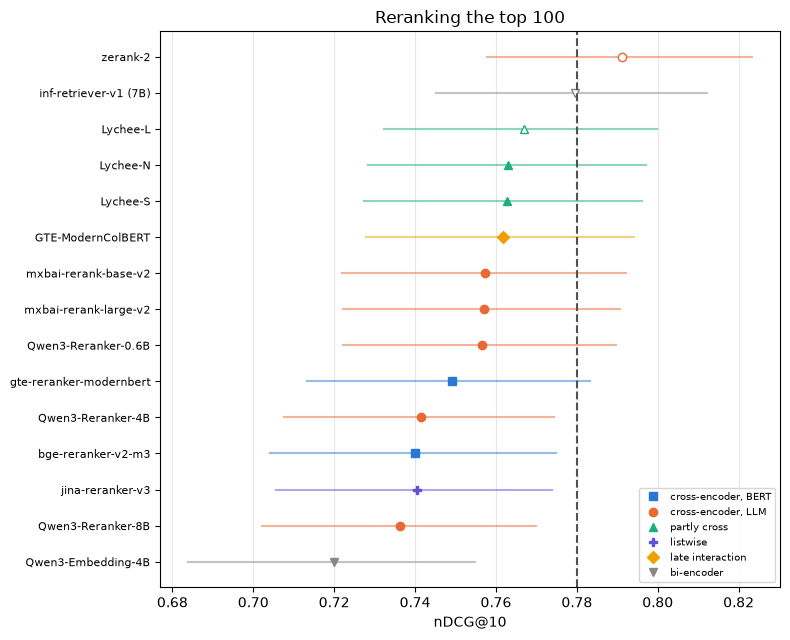

In [4]:
order = results.index[::-1]
run_of = {LABEL[run]: run for run in MODELS}
fig, ax = plt.subplots(figsize=(8, 6.5))
for y, label in enumerate(order):
    run = run_of[label]
    scores = ndcg(final(run))
    mean, low, high = bootstrap_ci(scores)
    filled = against_first(scores)[1] < RULE_P
    colour = COLOURS[TYPE[run]]
    ax.plot([low, high], [y, y], color=colour, alpha=0.5)
    ax.plot(
        mean, y, MARKERS[TYPE[run]], color=colour, markerfacecolor=colour if filled else "white"
    )
ax.axvline(base.mean(), color="#52514e", linestyle="--")
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set(xlabel="nDCG@10", title="Reranking the top 100")
ax.grid(axis="x", alpha=0.3)
handles = [
    plt.Line2D([], [], marker=MARKERS[t], color=c, linestyle="", label=t)
    for t, c in COLOURS.items()
]
ax.legend(handles=handles, fontsize=7, loc="lower right")
plt.tight_layout()

**Figure 1. nDCG@10 with 95% intervals after reranking the top 100.** Colour and marker by type. Dashed line: the first stage without a reranker. **Filled marker: significantly different from the first stage (p < 0.05); hollow: not.** Every filled marker is left of the line.

## 4. Reranking fewer candidates

Most rerankers score each product on its own, so reranking only the top 10, 20 or 50 can be read from the same scores: sort that many by the reranker, leave the rest in first-stage order. jina-reranker-v3 is listwise (its scores depend on the whole list) and is left out here.

In [5]:
depth_rows = []
for run in MODELS:
    if run in LISTWISE:
        continue
    row = {"model": LABEL[run], "type": TYPE[run]}
    for depth in DEPTHS:
        row[f"Δ @{depth}"], row[f"p @{depth}"] = against_first(ndcg(at_depth(run, depth)))
    depth_rows.append(row)
by_depth = pd.DataFrame(depth_rows).sort_values("Δ @10", ascending=False).set_index("model")
display(
    by_depth.style.map(type_style, subset=["type"])
    .apply(significance_colours, axis=1)
    .format({c: "{:+.1f}" if c.startswith("Δ") else "{:.3f}" for c in by_depth.columns[1:]})
)

,type,Δ @10,p @10,Δ @20,p @20,Δ @50,p @50,Δ @100,p @100
model,,,,,,,,,
zerank-2,"cross-encoder, LLM",+0.9,0.008,+1.4,0.057,+0.9,0.337,+1.1,0.254
mxbai-rerank-large-v2,"cross-encoder, LLM",+0.3,0.304,-0.3,0.667,-1.2,0.120,-2.3,0.005
inf-retriever-v1 (7B),bi-encoder,+0.1,0.643,-0.0,0.990,-0.1,0.904,-0.1,0.948
gte-reranker-modernbert,"cross-encoder, BERT",+0.0,0.961,-0.7,0.241,-2.2,0.001,-3.1,0.000
mxbai-rerank-base-v2,"cross-encoder, LLM",-0.0,0.919,-0.3,0.688,-1.7,0.041,-2.3,0.012
GTE-ModernColBERT,late interaction,-0.1,0.662,-0.6,0.317,-1.4,0.035,-1.8,0.007
Lychee-N,partly cross,-0.1,0.816,-0.4,0.480,-1.5,0.040,-1.7,0.030
Qwen3-Reranker-0.6B,"cross-encoder, LLM",-0.1,0.749,-0.5,0.469,-1.5,0.029,-2.4,0.002
Lychee-L,partly cross,-0.2,0.621,-0.3,0.703,-1.0,0.239,-1.3,0.140


**Table 3. Reranking the top 10, 20, 50 or 100**, against the first stage. Δ and p as in Table 2; green / red: significantly better / worse. **Only zerank-2 at depth 10 is significantly better. Every other model loses more the deeper it reranks.**

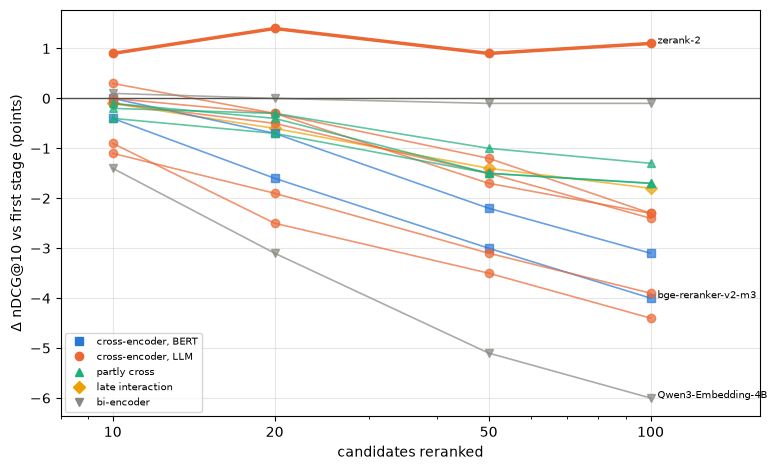

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for run in MODELS:
    if run in LISTWISE:
        continue
    deltas = [by_depth.loc[LABEL[run], f"Δ @{d}"] for d in DEPTHS]
    width = 2.5 if run == "rerank_zerank2" else 1.2
    ax.plot(
        DEPTHS,
        deltas,
        marker=MARKERS[TYPE[run]],
        color=COLOURS[TYPE[run]],
        linewidth=width,
        alpha=1 if run == "rerank_zerank2" else 0.7,
    )
    if run in ("rerank_zerank2", "rerank_qwen3_emb_4b", "rerank_bge_v2_m3"):
        ax.annotate(
            LABEL[run], (100, deltas[-1]), xytext=(5, 0), textcoords="offset points", fontsize=7
        )
ax.axhline(0, color="#52514e", linewidth=1)
ax.set(xscale="log", xlabel="candidates reranked", ylabel="Δ nDCG@10 vs first stage (points)")
ax.set_xticks(DEPTHS, [str(d) for d in DEPTHS])
ax.set_xlim(8, 160)
ax.grid(alpha=0.3)
ax.legend(handles=[h for h in handles if h.get_label() != "listwise"], fontsize=7, loc="lower left")
plt.tight_layout()

**Figure 2. Change in nDCG@10 as more candidates are reranked**, one line per model, colour and marker by type. Above the black line: better than the first stage. **zerank-2 (thick orange) is the only line above zero; the rest fall as depth grows.** The first stage's own order of the top 10 is hard to beat; rerankers mostly pull worse products up from further down.

## 5. zerank-2: the only one that helps

In [7]:
zerank = reranked["rerank_zerank2"]
zrows = []
for depth in (5, 10, 15, 20, 50):
    alone, mixed = {}, {}
    for q in dev:
        head = first_order[q][:depth]
        reordered = sorted(head, key=lambda p: -zerank[q][p])
        alone[q] = {p: -i for i, p in enumerate(reordered + first_order[q][depth:])}
        mix = rrf(
            [
                {q: {p: -i for i, p in enumerate(head)}},
                {q: {p: -i for i, p in enumerate(reordered)}},
            ]
        )[q]
        mixed[q] = {
            p: -i
            for i, p in enumerate(sorted(head, key=lambda p: -mix[p]) + first_order[q][depth:])
        }
    a_diff, a_p = against_first(ndcg(alone))
    m_diff, m_p = against_first(ndcg(mixed))
    zrows.append(
        {
            "depth": depth,
            "Δ alone": a_diff,
            "p alone": a_p,
            "Δ fused": m_diff,
            "p fused": m_p,
            "total p99, estimated (ms)": p99["rerank_zerank2"] * depth / 100 + FIRST_STAGE_MS,
        }
    )
zerank_table = pd.DataFrame(zrows).set_index("depth")
display(
    zerank_table.style.apply(significance_colours, axis=1)
    .map(budget_style, subset=["total p99, estimated (ms)"])
    .format(
        {
            "Δ alone": "{:+.1f}",
            "p alone": "{:.3f}",
            "Δ fused": "{:+.1f}",
            "p fused": "{:.3f}",
            "total p99, estimated (ms)": "{:,.0f}",
        }
    )
)

,Δ alone,p alone,Δ fused,p fused,"total p99, estimated (ms)"
depth,,,,,
5,+0.6,0.017,+0.4,0.008,251
10,+0.9,0.008,+0.7,0.001,464
15,+1.5,0.009,+1.1,0.002,677
20,+1.4,0.057,+1.3,0.001,890
50,+0.9,0.337,+1.6,0.004,"2,169"


**Table 4. zerank-2 by depth.** *Alone*: the reranker's order replaces the first stage's. *Fused*: the two orders combined with RRF. Δ and p against the first stage; green: significantly better. *Total p99, estimated*: the measured depth-100 p99 scaled by depth, plus the first stage; green within 500 ms. **Depth 10 is significant and just fits the budget, for +0.9 points, roughly one Exact product moving up a few places in a third of the queries.** That uses nearly the whole budget and leaves nothing for the LLM steps that come next, so it is not adopted.

## 6. What stands out

The numbers behind each observation; reasons are **untested ideas**.

In [8]:
def unlabelled(results: dict) -> float:
    top = rank({q: results[q] for q in dev}, 10)
    return sum(p not in labels.get(q, {}) for q in dev for p in top[q]) / (10 * len(dev))


checks = (
    pd.DataFrame(
        [
            {
                "system": "first stage",
                "type": "–",
                "unlabelled in top 10 (%)": 100 * unlabelled(first),
            }
        ]
        + [
            {
                "system": LABEL[run],
                "type": TYPE[run],
                "unlabelled in top 10 (%)": 100 * unlabelled(final(run)),
            }
            for run in MODELS
        ]
    )
    .sort_values("unlabelled in top 10 (%)")
    .set_index("system")
)
display(
    checks.style.map(lambda t: type_style(t) if t in COLOURS else "", subset=["type"])
    .background_gradient(cmap="Reds", subset=["unlabelled in top 10 (%)"])
    .format({"unlabelled in top 10 (%)": "{:.1f}"})
)

,type,unlabelled in top 10 (%)
system,,
first stage,–,14.1
zerank-2,"cross-encoder, LLM",14.1
inf-retriever-v1 (7B),bi-encoder,14.5
Qwen3-Reranker-0.6B,"cross-encoder, LLM",15.5
Lychee-L,partly cross,15.6
Lychee-S,partly cross,15.8
Lychee-N,partly cross,15.9
Qwen3-Reranker-4B,"cross-encoder, LLM",16.1
mxbai-rerank-base-v2,"cross-encoder, LLM",16.1


**Table 5. Share of the top 10 that WANDS never labelled** (after reranking the top 100). WANDS labels about 490 products per query; every other product counts as irrelevant, even a perfect match. Darker red: more unlabelled products. **The losing rerankers put 16–18% unlabelled products in the top 10, against 14% for the first stage and zerank-2**, so part of their loss is products that may be fine but cannot score.

- **Off-the-shelf rerankers are trained for questions and passages; WANDS is 2–4 keywords against product listings.** The same gap showed in notebook 04: MTEB rank did not carry over.
- **The first stage is already strong at the top.** It combines exact word matches (BM25) with two dense models; a single reranker throws that order away.
- **Same base, different training:** zerank-2 and Qwen3-Reranker-4B are both Qwen3-4B. zerank-2 helps, Qwen3-Reranker hurts (−1.1 at depth 10). Its prompt is word for word the official one; it was only tried with its default question-answering instruction.
- **Reading together beats reading apart, but neither beats the first stage:** Qwen3-Reranker-4B (cross) is −3.9 at depth 100, its bi-encoder sibling −6.0.
- **inf-7B as a reranker changes nothing** (−0.1): the first stage already contains its smaller sibling inf-1.5B.
- **Size does not help:** Qwen3-Reranker 0.6B → 4B → 8B gets worse (−2.4, −3.9, −4.4 at depth 100); Lychee N → L barely moves.

## 7. Takeaways

| Question | Answer |
|---|---|
| Does an off-the-shelf reranker improve the top 10? | **No**, except zerank-2 at depth 10 (+0.9, p=0.008). |
| Does reranking more candidates help? | **No**: it hurts almost every model. |
| Is zerank-2 worth it? | **Not now**: ~470 ms of the 500 ms budget for +0.9 points. |
| Which type works best? | No type wins; training matters more (zerank-2 vs Qwen3-Reranker, same base). |

**Decision:** no reranker for now; the first stage alone (37 ms) stays. **Next: LLM query expansion and product-description expansion**, each tested with ablations. Rerankers are revisited after that, including rerankers fine-tuned on WANDS.

**Caveats:** off-the-shelf only; unlabelled products count as irrelevant (Table 5); latency at depths below 100 is estimated, not measured.